# Week 6 (continued) — Attacking the Detector: Typos and Paraphrasing

**Threat model:** a student has an AI-written essay and wants the detector to say "human", **without changing what the essay says**. We try cheap, realistic edits and measure how far detection falls.

Attacks, from crude to sophisticated:
1. **Typo injection:** corrupt 2%, 5% or 10% of words with one character edit (swap, delete, or double a letter). Kaggle's hidden test set for this exact competition added character noise, because detectors learn "typos → human" from student essays (`10_zero_shot` found perplexity tracks misspellings).
2. **Our seq2seq paraphraser** (`12`): the from-scratch GRU + attention model, sampling.
3. **Pretrained T5 paraphraser** (`Vamsi/T5_Paraphrase_Paws`, T5-base fine-tuned on Google's PAWS paraphrase pairs) at two strengths (sampling temperature 1.0 and 1.5).
4. **T5 + 5% typos** combined.

For every attack we measure, side by side:
- **detection rate** of AI essays: fine-tuned DistilRoBERTa at its 1%-FPR threshold (`09`), and TF-IDF + LinearSVM at its default threshold;
- **human false-positive rate** after the *same* edit (does editing make human essays look more AI?);
- **% of words changed**: an attack that rewrites half the essay is no longer "the same essay";
- **fluency:** GPT-2 log-perplexity (`10`). Garbled text scores high.

An attack only "works" if detection drops **while** the edit stays small and fluent.

In [1]:
import os
import sys
sys.path.append('..')
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import gc
import time
import difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from src.data import load_splits
from src.detector import Detector
from src.paraphraser import Seq2SeqParaphraser, T5Paraphraser, inject_typos

transformers.logging.set_verbosity_error()
SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 100)
HUMAN, AI = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e3', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#9a9a94', 'axes.titleweight': 'bold'})

## Step 1 — The essays under attack

All **on-topic**, so the detector can't lean on the topic shortcut (`06`):
- every on-topic AI essay in `test`;
- 300 on-topic essays from the **held-out generators** (Claude, Falcon), which the detector never saw in training;
- 300 on-topic **human** essays from `test`, as the control group.

In [2]:
data = load_splits()
on = data[data['on_topic']]
ai_test = on[(on['split'] == 'test') & (on['label'] == 1)]
ai_gen = on[on['split'] == 'heldout_generator'].sample(min(300, (on['split'] == 'heldout_generator').sum()), random_state=SEED)
human = on[(on['split'] == 'test') & (on['label'] == 0)].sample(300, random_state=SEED)
essays = pd.concat([ai_test.assign(group='AI (test)'), ai_gen.assign(group='AI (held-out generator)'), human.assign(group='human (test)')])
print(essays['group'].value_counts())

group
AI (test)                  473
AI (held-out generator)    300
human (test)               300
Name: count, dtype: int64


## Step 2 — Build every attacked version

Each attack produces a full rewritten copy of every essay. Paraphrasers work **sentence by sentence** and keep paragraph breaks (`src/paraphraser.py`). After paraphrasing, **spacing artefacts are cleaned**: T5 writes "monkey ." with a space before the full stop. Left in, that would be a new surface signal (like the leading whitespace found in `03`), and a change in detection could come from the stray spaces instead of the paraphrase.

The seq2seq only rewrites sentences up to 48 tokens (its training limit); longer sentences pass through unchanged.

In [3]:
texts = essays['text'].tolist()
versions = {'original': texts}
for rate in [0.02, 0.05, 0.10]:
    versions[f'typos {rate:.0%}'] = [inject_typos(t, rate, seed=SEED + i) for i, t in enumerate(texts)]

t0 = time.time()
s2s = Seq2SeqParaphraser()
versions['seq2seq (ours, sampled)'] = s2s.paraphrase_essays(texts, sample=True, temperature=0.8, top_k=10, seed=SEED)
del s2s; gc.collect(); torch.cuda.empty_cache()
print(f"seq2seq: {(time.time() - t0) / 60:.1f} min")

t0 = time.time()
t5 = T5Paraphraser()
versions['T5 paraphrase (T=1.0)'] = t5.paraphrase_essays(texts, temperature=1.0, seed=SEED)
versions['T5 paraphrase (T=1.5)'] = t5.paraphrase_essays(texts, temperature=1.5, seed=SEED)
del t5; gc.collect(); torch.cuda.empty_cache()
versions['T5 (T=1.0) + typos 5%'] = [inject_typos(t, 0.05, seed=SEED + i) for i, t in enumerate(versions['T5 paraphrase (T=1.0)'])]
print(f"T5: {(time.time() - t0) / 60:.1f} min | {len(versions)} versions of {len(texts)} essays")

seq2seq: 1.4 min


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

T5: 11.0 min | 8 versions of 1073 essays


## Step 3 — How big and how fluent is each edit?

- **% of words changed:** align the original and attacked word sequences (`difflib`, the same idea as the Unix `diff`) and count words inserted, deleted or replaced.
- **Fluency:** GPT-2's log-perplexity on the first 512 tokens, as in `10`. Typos and garbled paraphrases make text more surprising to GPT-2.

(Memory note: GPT-2 scores all 50,257 vocabulary entries at every position, so one batch's score tensor is ~0.8 GB in fp32. The first full run of this notebook ran out of GPU memory because the previous batch's tensor was still alive when the next one was computed. Hence the explicit `del` and the batch size of 4.)

In [4]:
def words_changed(a, b):
    wa, wb = a.split(), b.split()
    ops = difflib.SequenceMatcher(None, wa, wb, autojunk=False).get_opcodes()
    return sum(max(i2 - i1, j2 - j1) for op, i1, i2, j1, j2 in ops if op != 'equal') / max(len(wa), 1)

gpt_tok = AutoTokenizer.from_pretrained('gpt2'); gpt_tok.pad_token = gpt_tok.eos_token
gpt = AutoModelForCausalLM.from_pretrained('gpt2').to('cuda').eval()

@torch.no_grad()
def log_ppl(texts, batch_size=4):
    enc = gpt_tok(texts, truncation=True, max_length=512)['input_ids']
    out = np.zeros(len(enc), dtype=np.float32)
    order = np.argsort([len(x) for x in enc], kind='stable')
    for s in range(0, len(order), batch_size):
        chunk = order[s:s + batch_size]
        x = torch.full((len(chunk), max(len(enc[i]) for i in chunk)), gpt_tok.eos_token_id, dtype=torch.long)
        m = torch.zeros_like(x)
        for r, i in enumerate(chunk):
            x[r, :len(enc[i])] = torch.tensor(enc[i]); m[r, :len(enc[i])] = 1
        x, m = x.cuda(), m.cuda()
        with torch.autocast('cuda', dtype=torch.float16):
            logits = gpt(input_ids=x, attention_mask=m).logits[:, :-1].float()
        nll = F.cross_entropy(logits.transpose(1, 2), x[:, 1:], reduction='none')
        mm = m[:, 1:].float()
        out[chunk] = ((nll * mm).sum(1) / mm.sum(1)).cpu().numpy()
        del logits, nll   # free this batch's ~0.8 GB score tensor before the next batch (forgetting this ran the GPU out of memory)
    return out

t0 = time.time()
change = {v: np.array([words_changed(a, b) for a, b in zip(texts, versions[v])]) for v in versions}
fluency = {v: log_ppl(versions[v]) for v in versions}
del gpt; gc.collect(); torch.cuda.empty_cache()
print(f"edit size and fluency computed in {(time.time() - t0) / 60:.1f} min")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

edit size and fluency computed in 5.1 min


## Step 4 — Score every version with both detectors

- **DistilRoBERTa** (`08`) at the threshold chosen in `09` for a 1% false-positive rate on val humans (logit 4.67).
- **TF-IDF + LinearSVM** (`04`), refit on `train` exactly as before, at its default threshold (0). `09` showed its default is the safe choice.

In [5]:
det = Detector()
THR = det.thresholds[0.01]
train = data[data['split'] == 'train']
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True).fit(train['text'])
svm = LinearSVC(C=1).fit(vec.transform(train['text']), train['label'])

t0 = time.time()
scores = {v: {'roberta': det.score(versions[v]), 'tfidf': svm.decision_function(vec.transform(versions[v]))} for v in versions}
print(f"scored {len(versions)} x {len(texts)} essays in {(time.time() - t0) / 60:.1f} min")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

scored 8 x 1073 essays in 0.7 min


In [6]:
groups = essays['group'].to_numpy()
rows = []
for v in versions:
    r = {'attack': v}
    for det_name, col, thr in [('DistilRoBERTa', 'roberta', THR), ('TF-IDF', 'tfidf', 0.0)]:
        flagged = scores[v][col] >= thr
        r[f'{det_name}: % AI caught (test)'] = flagged[groups == 'AI (test)'].mean() * 100
        r[f'{det_name}: % AI caught (held-out gen)'] = flagged[groups == 'AI (held-out generator)'].mean() * 100
        r[f'{det_name}: % humans flagged'] = flagged[groups == 'human (test)'].mean() * 100
    ai = groups != 'human (test)'
    r['% words changed (AI essays)'] = change[v][ai].mean() * 100
    r['GPT-2 log-ppl (AI essays)'] = np.median(fluency[v][ai])
    rows.append(r)
table = pd.DataFrame(rows).set_index('attack')
table.round(1).T

attack,original,typos 2%,typos 5%,typos 10%,"seq2seq (ours, sampled)",T5 paraphrase (T=1.0),T5 paraphrase (T=1.5),T5 (T=1.0) + typos 5%
DistilRoBERTa: % AI caught (test),99.6,99.4,99.4,98.9,67.9,99.6,96.4,98.9
DistilRoBERTa: % AI caught (held-out gen),100.0,100.0,99.3,98.3,48.3,99.7,96.0,98.7
DistilRoBERTa: % humans flagged,0.7,0.3,0.0,0.0,0.0,2.7,0.3,0.3
TF-IDF: % AI caught (test),98.7,98.5,98.7,98.5,89.6,98.3,94.7,97.9
TF-IDF: % AI caught (held-out gen),87.0,85.3,84.7,85.0,40.3,85.0,74.7,83.7
TF-IDF: % humans flagged,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
% words changed (AI essays),0.0,1.6,4.0,8.2,60.6,15.3,42.6,19.0
GPT-2 log-ppl (AI essays),2.3,2.6,3.0,3.5,3.8,2.5,3.1,3.1


How to read it: compare each column with `original`. A strong attack lowers **% AI caught** while keeping **% words changed** small and **log-ppl** close to the original. The **% humans flagged** row checks that the same edit doesn't make honest essays look like AI.

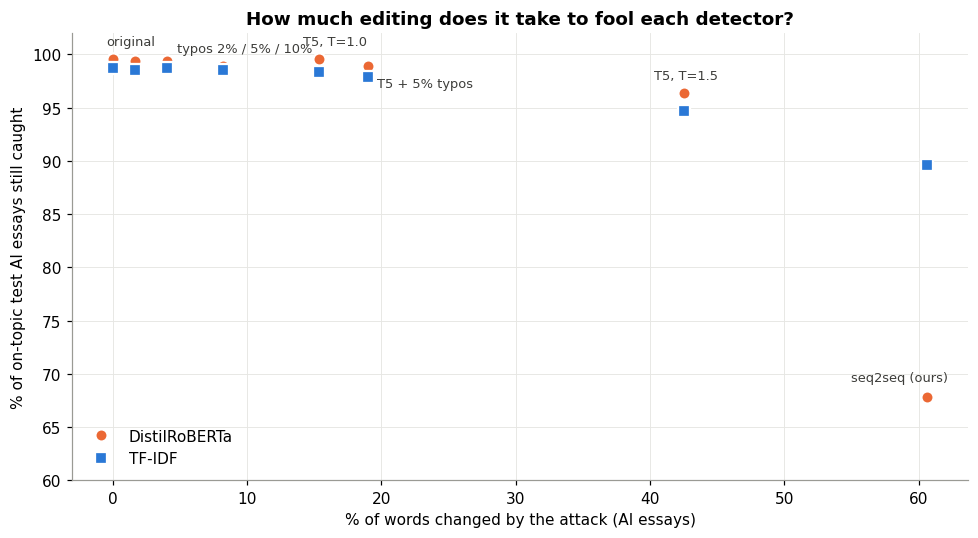

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for det_name, color, marker in [('DistilRoBERTa', AI, 'o'), ('TF-IDF', HUMAN, 's')]:
    x = table['% words changed (AI essays)']
    y = table[f'{det_name}: % AI caught (test)']
    ax.plot(x, y, linestyle='none', marker=marker, markersize=8, color=color, label=det_name,
            markeredgecolor='white', markeredgewidth=1.5, zorder=3)
# label each attack once, next to its DistilRoBERTa point; the three typo rates sit together, so they share one label
labels = {'original': ('original', (-4, 9)), 'typos 10%': ('typos 2% / 5% / 10%', (-30, 9)),
          'seq2seq (ours, sampled)': ('seq2seq (ours)', (-50, 10)), 'T5 paraphrase (T=1.0)': ('T5, T=1.0', (-10, 9)),
          'T5 paraphrase (T=1.5)': ('T5, T=1.5', (-20, 9)), 'T5 (T=1.0) + typos 5%': ('T5 + 5% typos', (6, -14))}
for attack, (text, offset) in labels.items():
    r = table.loc[attack]
    ax.annotate(text, (r['% words changed (AI essays)'], r['DistilRoBERTa: % AI caught (test)']),
                xytext=offset, textcoords='offset points', fontsize=8.5, color='#3d3d3a')
ax.set_xlabel('% of words changed by the attack (AI essays)')
ax.set_ylabel('% of on-topic test AI essays still caught')
ax.set_ylim(60, 102)
ax.set_title('How much editing does it take to fool each detector?', fontsize=12)
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig('../images/13_attack.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 5 — Read the attacked text

Numbers alone can hide that an "attack" destroyed the essay. One AI essay (opening sentences) under every attack, with its DistilRoBERTa score (logit; flagged if ≥ the threshold):

In [8]:
i = int(np.flatnonzero(groups == 'AI (test)')[3])
print(f"threshold (1% FPR): logit {THR:.2f}\n")
for v in versions:
    s = scores[v]['roberta'][i]
    print(f"--- {v}  | logit {s:.2f} -> {'FLAGGED as AI' if s >= THR else 'passes as human'} | {change[v][i] * 100:.0f}% words changed")
    print(versions[v][i][:420].replace('\n', ' '), '...\n')

threshold (1% FPR): logit 4.67

--- original  | logit 9.76 -> FLAGGED as AI | 0% words changed
Graduating high school early is a topic that has been debated for many years. Some people believe that graduating early is a good thing, while others believe that it is not. In this essay, I will discuss the pros and cons of graduating high school early compared to graduating within four years.  One of the main benefits of graduating high school early is that it allows students to start their college education sooner ...

--- typos 2%  | logit 9.74 -> FLAGGED as AI | 2% words changed
Graduating high school early is a topic that has been debated for many years. Some people believe that graduating early is a good thing, while others believe that it is not. In this essay, I will discuss the pros and cons of graduating high school early compared to graduating within four years.  One of the main bennefits of graduating high school early is that it allows students to start their college education s

## Step 6 — Why do typos work?

If small typos move the detector a lot, the reason should show in *what* the typos change. Two checks:
- **Score shift vs typo rate** for AI essays: how far the median logit moves at each typo rate.
- **Human essays** already contain typos. Do the human essays the detector is most confident about have more or fewer misspellings than the rest? (Misspelling proxy: share of words outside GloVe's vocabulary, as in `10`.)

In [9]:
ai = groups == 'AI (test)'
for v in ['original', 'typos 2%', 'typos 5%', 'typos 10%']:
    print(f"{v:10s} median DistilRoBERTa logit on AI essays: {np.median(scores[v]['roberta'][ai]):6.2f}   "
          f"(TF-IDF: {np.median(scores[v]['tfidf'][ai]):5.2f})")

import gensim.downloader as gensim_api
from gensim.utils import simple_preprocess
glove_vocab = set(gensim_api.load('glove-wiki-gigaword-100').key_to_index)
oov = lambda t: np.mean([w not in glove_vocab for w in simple_preprocess(t, min_len=1, max_len=30)] or [0])
h = groups == 'human (test)'
h_scores = scores['original']['roberta'][h]
h_oov = np.array([oov(t) for t in np.array(texts, dtype=object)[h]])
q = np.quantile(h_scores, [0.25, 0.75])
print(f"\nhuman essays the detector finds MOST human (bottom quarter of logits): misspelling proxy {np.median(h_oov[h_scores <= q[0]]) * 100:.2f}% of words")
print(f"human essays the detector finds LEAST human (top quarter of logits):   misspelling proxy {np.median(h_oov[h_scores >= q[1]]) * 100:.2f}% of words")

original   median DistilRoBERTa logit on AI essays:   9.75   (TF-IDF:  1.28)
typos 2%   median DistilRoBERTa logit on AI essays:   9.73   (TF-IDF:  1.26)
typos 5%   median DistilRoBERTa logit on AI essays:   9.70   (TF-IDF:  1.24)
typos 10%  median DistilRoBERTa logit on AI essays:   9.65   (TF-IDF:  1.18)



human essays the detector finds MOST human (bottom quarter of logits): misspelling proxy 1.43% of words
human essays the detector finds LEAST human (top quarter of logits):   misspelling proxy 0.20% of words


## Step 7 — Save

In [10]:
table.round(2).to_csv('../results/13_attack.csv')
print(table.round(1).T)

attack                                     original  typos 2%  typos 5%  typos 10%  seq2seq (ours, sampled)  T5 paraphrase (T=1.0)  T5 paraphrase (T=1.5)  T5 (T=1.0) + typos 5%
DistilRoBERTa: % AI caught (test)              99.6      99.4      99.4       98.9                     67.9                   99.6                   96.4                   98.9
DistilRoBERTa: % AI caught (held-out gen)     100.0     100.0      99.3       98.3                     48.3                   99.7                   96.0                   98.7
DistilRoBERTa: % humans flagged                 0.7       0.3       0.0        0.0                      0.0                    2.7                    0.3                    0.3
TF-IDF: % AI caught (test)                     98.7      98.5      98.7       98.5                     89.6                   98.3                   94.7                   97.9
TF-IDF: % AI caught (held-out gen)             87.0      85.3      84.7       85.0                     40.3        

## Key takeaways

- **Typos don't fool the detector.** Corrupting 10% of words leaves DistilRoBERTa catching **98.9%** of test AI essays (from 99.6%) and 98.3% of held-out-generator essays; its median logit barely moves (9.75 → 9.65, threshold 4.67). TF-IDF is equally unmoved. Typos *are* a human signal (the human essays the detector finds most human have ~7× the misspelling rate of those it finds least human: 1.43% vs 0.20% of words), but the AI-style signal in the rest of the essay outweighs a few misspellings.
- **Light paraphrasing doesn't fool it either.** T5 at temperature 1.0 changes 15% of words and fluency stays close to the original (GPT-2 log-ppl 2.5 vs 2.3); detection stays at **99.6%**. Adding 5% typos on top: 98.9%.
- **Heavy paraphrasing barely dents it.** T5 at temperature 1.5 rewrites **43%** of words (the text gets odd: "a rising hex high school") and DistilRoBERTa still catches **96.4%** (held-out generators 96.0%). TF-IDF suffers more on unseen generators: 87.0% → 74.7%.
- **Only our seq2seq lowers detection substantially (to 67.9% test, 48.3% held-out generators), but only by changing 61% of the words** and producing the least fluent text of all (log-ppl 3.8). As `12` showed, its changes break meaning ("The high school high school is a topic…"). That's not a successful attack, it's a damaged essay. Even then, the example essay stayed flagged after 41% of its words changed.
- **Fairness check:** after T5 paraphrasing (T=1.0), human essays are flagged **2.7%** of the time vs 0.7% originally (8 vs 2 essays of 300, so a small sample). Running honest work through a paraphrasing tool can make it look *more* machine-written. The demo's "try to fool it" button should show this too, by paraphrasing a human essay.
- **DistilRoBERTa is more robust than TF-IDF under paraphrase,** especially on unseen generators, consistent with `08`'s finding that the pretrained model generalises better.
- **Limits of this test:** both attackers are sentence-level light editors trained on question/encyclopedia data. A determined student would use an LLM "humaniser" that rewrites at the paragraph level and imitates student style. That attack isn't tested here (it would need a much larger model than fits on this GPU), so "robust to attack" means robust **to these attacks**, not in general.
